# 특성공학과 규제(과대적합,과소적합)
문제: 농어의 길이를 보고 무게를 맞춰보자

## ○ 과대적합, 과소적합
* 과대적합(overfitting)
   - 훈련세트에서는 평가 점수가 좋은데, 테스트세트에서는 평가 점수가 낮을 때
   - 모델이 훈련세트에 너무 집착해서 데이터에 내재된 거시적인 패턴을 감지하지 못한 경우
   - 실전에 투입할 때 잘 작동하지 않을 가능성 높음
* 과소적합(underfitting)
   - 훈련세트보다 테스트세트가 점수가 높거나
   - 훈련세트, 테스트세트 모두 낮은 경우
   - 모델이 너무 단순하여 훈련 세트를 통해 적절한 훈련이 이루어지지 않은 경우
   - 훈련세트, 테스트세트의 크기가 매우 작을 때 발생할 가능성 높음<br>
   <img src="https://drive.google.com/uc?id=1KTDo8jKth5DN5-zUyvU0l4gDyM71uYjS" height=250 width=400>

## ○ 선형회귀에서의 문제점

### 1)데이터셋 준비

In [ ]:
import numpy as np

# 농어 데이터셋
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [ ]:
from sklearn.model_selection import train_test_split

# 훈련 세트, 테스트 세트 나누기
train_input, test_input, train_target, test_target = train_test_split(
    perch_length, perch_weight, random_state=42)

# 훈련 세트, 테스트 세트 2차원 배열로 변환
# reshape(-1, 1)의 의미 행은 자동으로, 열은 1개
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)

### 2)선형 회귀 모델 적용

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lr = LinearRegression()
# 선형 회귀 모델 훈련
lr.fit(train_input, train_target)

LinearRegression()

In [ ]:
# 50cm 농어에 대한 예측
print(lr.predict([[50]]))

[1241.83860323]


In [ ]:
# 선형회귀(LinearRegression)을 통해 찾은
# lr 객체의 기울기 속성과 y절편 속성: coef_, intercept_
print(lr.coef_, lr.intercept_)

[39.01714496] -709.0186449535477


### 3)인공지능 모델 평가


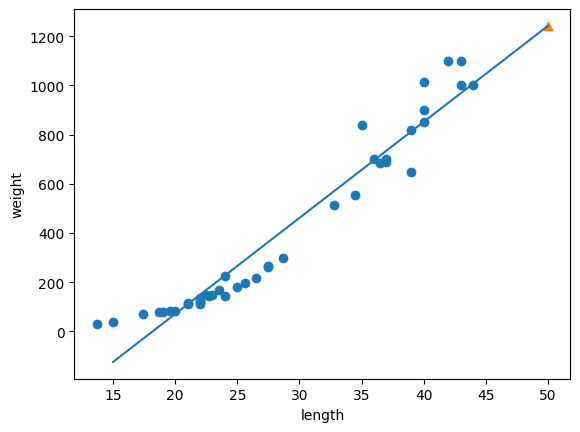

In [ ]:
# 훈련 세트의 산점도 그래프
import matplotlib.pyplot as plt
plt.scatter(train_input, train_target)

# lr 객체의 기울기 속성과 y절편 값을 이용하여
# 15에서 50까지 1차 방정식 그래프 표시
plt.plot([15, 50], [15*lr.coef_+lr.intercept_, 50*lr.coef_+lr.intercept_])

# 50cm 농어 데이터(lr 객체를 통해 예측한 무게값(1241.8)) 표시
plt.scatter(50, 1241.8, marker='^')
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [ ]:
# 정확도 확인: 문제점은 없는가?
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

0.939846333997604
0.8247503123313558


### 4)다항회귀
* 길이에 대해 $길이^2$ 특성 추가
* 길이에 대한 2차 방정식인데 선형회귀라고 할 수 있을까?
* $길이^2$ 특성을 간단한 다른 변수로 치환하면, 가령 $길이^2$를 '왕길이'라고 한다면 $무게=a*왕길이+b*길이+c$ 형태의 선형 관계가 됨

<img src="https://drive.google.com/uc?id=1oymYeHTIkYjRkU4-IilAc6aq8pDdACa0" height=250 width=350>

In [ ]:
# 길이 특성을 활용한 특성 추가
train_poly = np.column_stack((train_input ** 2, train_input))
test_poly = np.column_stack((test_input ** 2, test_input))

In [ ]:
print(train_poly.shape, test_poly.shape)

(42, 2) (14, 2)


In [ ]:
lr = LinearRegression()
lr.fit(train_poly, train_target)

print(lr.predict([[50**2, 50]]))

[1573.98423528]


In [ ]:
print(lr.coef_, lr.intercept_)

[  1.01433211 -21.55792498] 116.0502107827827


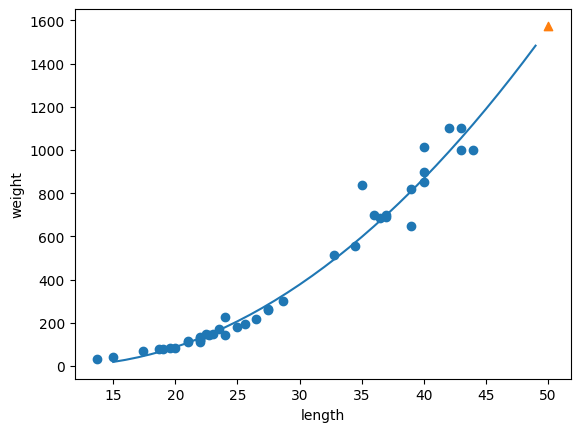

In [ ]:
# 훈련세트 산점도 그래프 표시
plt.scatter(train_input, train_target)

# 구간별 직선을 그리기 위한 x축 값(15~49 정수 배열) 생성
point = np.arange(15, 50)

# 15에서 49까지 선형 그래프 표시
# 기울기 값과 절편 적용하여 y축 값 계산하여 그래프 표시
plt.plot(point, 1.01*point**2 - 21.6*point + 116.05)

# 50cm 농어 데이터
plt.scatter([50], [1574], marker='^')

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [ ]:
# 정확도 확인
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.9706807451768623
0.9775935108325122


## ○ 특성 공학
* 특성 공학이란?
    - 기존의 특성을 사용하여 새로운 특성을 뽑아내는 작업
    - 사용하는 이유: 모델이 패턴을 더 잘 배우도록 추가 정보를 주는 것

### 1)데이터셋 준비

In [ ]:
# perch_full.csv 파일 코랩에 업로드
from google.colab import files
myfile = files.upload()

Saving perch_full.csv to perch_full.csv


In [ ]:
import pandas as pd
df = pd.read_csv('perch_full.csv')
df.head()

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43
3,16.2,4.59,2.63
4,17.4,4.59,2.94


In [ ]:
perch_full = df.to_numpy() # 판다스 프레임을 넘파이배열로 변환
print(perch_full)

[[ 8.4   2.11  1.41]
 [13.7   3.53  2.  ]
 [15.    3.82  2.43]
 [16.2   4.59  2.63]
 [17.4   4.59  2.94]
 [18.    5.22  3.32]
 [18.7   5.2   3.12]
 [19.    5.64  3.05]
 [19.6   5.14  3.04]
 [20.    5.08  2.77]
 [21.    5.69  3.56]
 [21.    5.92  3.31]
 [21.    5.69  3.67]
 [21.3   6.38  3.53]
 [22.    6.11  3.41]
 [22.    5.64  3.52]
 [22.    6.11  3.52]
 [22.    5.88  3.52]
 [22.    5.52  4.  ]
 [22.5   5.86  3.62]
 [22.5   6.79  3.62]
 [22.7   5.95  3.63]
 [23.    5.22  3.63]
 [23.5   6.28  3.72]
 [24.    7.29  3.72]
 [24.    6.38  3.82]
 [24.6   6.73  4.17]
 [25.    6.44  3.68]
 [25.6   6.56  4.24]
 [26.5   7.17  4.14]
 [27.3   8.32  5.14]
 [27.5   7.17  4.34]
 [27.5   7.05  4.34]
 [27.5   7.28  4.57]
 [28.    7.82  4.2 ]
 [28.7   7.59  4.64]
 [30.    7.62  4.77]
 [32.8  10.03  6.02]
 [34.5  10.26  6.39]
 [35.   11.49  7.8 ]
 [36.5  10.88  6.86]
 [36.   10.61  6.74]
 [37.   10.84  6.26]
 [37.   10.57  6.37]
 [39.   11.14  7.49]
 [39.   11.14  6.  ]
 [39.   12.43  7.35]
 [40.   11.93

In [ ]:
import numpy as np

perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [ ]:
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target = train_test_split(perch_full, perch_weight, random_state=42)

### 2)사이킷런의 변환기: PolynomialFeatures()
* 변환기란? 사이킷런이 제공하는 클래스. 특성을 만들거나 전처리할 때 사용
* 변환기는 다양한 종류가 있음. 특성을 추가하는 PolynomialFeatures()나 데이터를 표준화하는 StandardScaler() 등도 변환기임.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
# include_bias=False 옵션을 사용하면 특성에 추가되는 절편 항 무시
poly = PolynomialFeatures(include_bias=False)

poly.fit(train_input)  # 사이킷런은 fit 시킨 후 transform 하도록 구성됨
train_poly = poly.transform(train_input)

In [ ]:
print(train_poly.shape)

(42, 9)


In [ ]:
# perch_full의 시리즈(특성)들: length(x0) height(x1)	width(x2)
poly.get_feature_names_out()

array(['x0', 'x1', 'x2', 'x0^2', 'x0 x1', 'x0 x2', 'x1^2', 'x1 x2',
       'x2^2'], dtype=object)

In [ ]:
test_poly = poly.transform(test_input)

### 3)다중 회귀 모델 훈련하기

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(train_poly, train_target)

LinearRegression()

In [ ]:
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.9903183436982125
0.9714559911594111


### 4)특성을 더 추가하면 결과가 더 좋아질까?
* 특성의 개수를 크게 늘리면 선형 모델이 아주 강력해져서 훈련세트에서는 거의 완벽하게 학습
* 하지만 훈련세트에 너무 과대적합되므로 테스트세트에서는 형편없는 점수를 받을 수 있음


In [ ]:
# degree 매개변수: 고차항의 최대 차수 지정
# degree=5 : 5제곱까지 특성 추가
poly = PolynomialFeatures(degree=5, include_bias=False)

poly.fit(train_input)
train_poly = poly.transform(train_input)
test_poly = poly.transform(test_input)

In [ ]:
print(train_poly.shape)

(42, 55)


In [ ]:
lr.fit(train_poly, train_target)

LinearRegression()

In [ ]:
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.9999999999996433
-144.40579436844948


## ○ 선형회귀 모델에서의 규제
* 규제란?
   - 많은 특성은 그대로 유지하면서, 인공지능 모델이 훈련세트에 과대적합되지 않도록 만들기 위해 사용
* 규제 시 하이퍼파라미터: alpha(규제 강도)
   - alpha 값이 크면 규제 강도가 세지므로 계수 값을 더 줄이고 조금 더 과소적합되도록 유도
   - alpha 값이 작으면 규제 강도가 약해지므로 계수가 덜 줄어들므로 과대적합될 가능성이 높아짐
* 릿지(Ridge)와 라쏘(Lasso)의 차이<br><img src="https://drive.google.com/uc?id=1kp-Z8Wg2QQ0IkEln9pJTjv5jbud7dxHB" height=240 width=500>
* 규제를 사용할 때는 특성에 대한 **정규화**가 꼭 필요함.

In [ ]:
# 정규화: 추가한 특성들도 정규화할 필요가 있음
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(train_poly)

train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

### 1)릿지
* 릿지: "여러 특성을 유지하되 영향력을 줄이자"


In [ ]:
from sklearn.linear_model import Ridge

ridge = Ridge()
ridge.fit(train_scaled, train_target)

Ridge()

In [ ]:
print(ridge.score(train_scaled, train_target))
print(ridge.score(test_scaled, test_target))

0.9896101671037343
0.9790693977615387


In [ ]:
import matplotlib.pyplot as plt

train_score = []
test_score = []

In [ ]:
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100] # 10배씩 증가
for alpha in alpha_list:
    # 릿지 모델 생성
    ridge = Ridge(alpha=alpha)
    # 릿지 모델 훈련
    ridge.fit(train_scaled, train_target)
    # 훈련 점수와 테스트 점수 저장
    train_score.append(ridge.score(train_scaled, train_target))
    test_score.append(ridge.score(test_scaled, test_target))

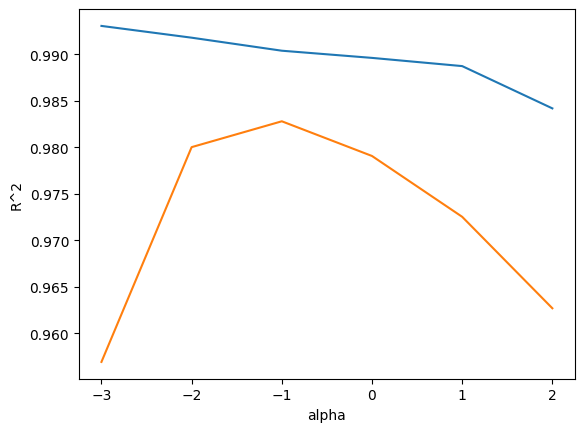

In [ ]:
plt.plot(np.log10(alpha_list), train_score) # alpha값이 등간격으로 표시되도록 log10처리
plt.plot(np.log10(alpha_list), test_score)
plt.xlabel('alpha')
plt.ylabel('R^2')
plt.show()

In [ ]:
ridge = Ridge(alpha=0.1)
ridge.fit(train_scaled, train_target)

print(ridge.score(train_scaled, train_target))
print(ridge.score(test_scaled, test_target))

0.9903815817570367
0.9827976465386928


### 2)라쏘
* 라쏘: "일부 특성은 아예 사용하지 말자"

In [ ]:
from sklearn.linear_model import Lasso

lasso = Lasso()
lasso.fit(train_scaled, train_target)

Lasso()

In [ ]:
print(lasso.score(train_scaled, train_target))
print(lasso.score(test_scaled, test_target))

0.989789897208096
0.9800593698421883


In [ ]:
train_score = []
test_score = []

alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
for alpha in alpha_list:
    # 라쏘 모델 생성
    lasso = Lasso(alpha=alpha, max_iter=10000)
    # 라쏘 모델 훈련
    lasso.fit(train_scaled, train_target)
    # 훈련 점수와 테스트 점수 저장
    train_score.append(lasso.score(train_scaled, train_target))
    test_score.append(lasso.score(test_scaled, test_target))

# ConvergenceWarning은 지정한 반복횟수가 부족할 때 나타나는 경고. 여기서는 무시

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.878e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.297e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(


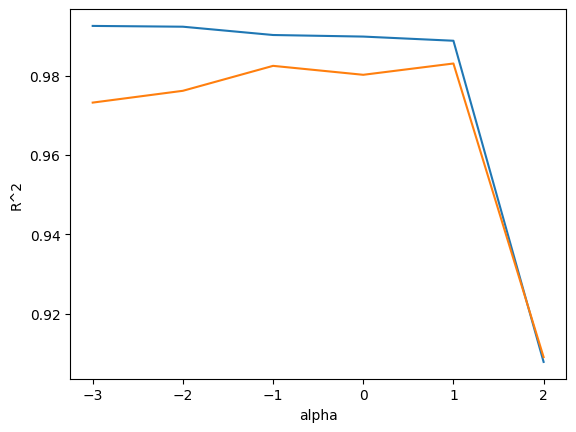

In [ ]:
plt.plot(np.log10(alpha_list), train_score)  # alpha값이 등간격으로 표시되도록 log10처리
plt.plot(np.log10(alpha_list), test_score)
plt.xlabel('alpha')
plt.ylabel('R^2')
plt.show()

In [ ]:
lasso = Lasso(alpha=10)
lasso.fit(train_scaled, train_target)

print(lasso.score(train_scaled, train_target))
print(lasso.score(test_scaled, test_target))

0.9888067471131867
0.9824470598706695
